# ПР-3. Аппроксимация ряда гармонической моделью: пакетный и стохастический градиентный спуск

Параметры для k=1:
L = 0.1
omega = 100.0000
dt = 0.006283

Генерация ряда из 500 значений...


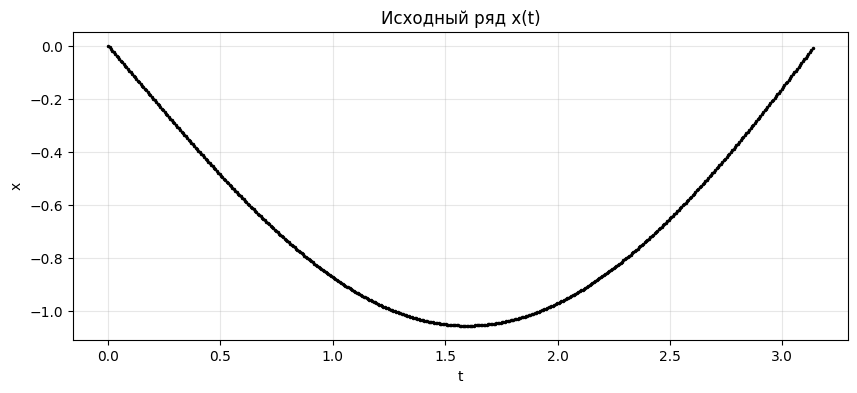

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from time import time

# Параметры для вашего k меняет направление старта. Чет вверх, нечёт вниз 
k = 1
L = k/10
omega = 100/k 
dt = 2*np.pi/1000

print(f"Параметры для k={k}:")
print(f"L = {L}")
print(f"omega = {omega:.4f}")
print(f"dt = {dt:.6f}")

# 1. Генерация ряда данных
n_points = 500
x = np.zeros(n_points)
x[0] = 0
x[1] = (-1)**k * dt

print(f"\nГенерация ряда из {n_points} значений...")
for i in range(n_points-2):
            #x’’ − L·(1 − x²)·x’ + x = sin(ωt).
    x[i+2] = (x[i+1]*(2+dt*L*(1-x[i]**2)) -
              x[i]*(1+dt**2+dt*L*(1-x[i]**2)) +
              dt**2*np.sin(omega*i*dt))

t = np.arange(n_points) * dt

plt.figure(figsize=(10, 4))
plt.plot(t, x, 'k.', ms=3)
plt.title('Исходный ряд x(t)')
plt.xlabel('t'); plt.ylabel('x'); plt.grid(alpha=0.3)
plt.show()

# Функция гармонической модели(вычисление предсказания пути модели)
def harmonic_model(params, t):
    a0, a1, b1, a2, b2, om1, om2 = params
    return (a0 + a1*np.cos(om1*t) + b1*np.sin(om1*t) +
            a2*np.cos(om2*t) + b2*np.sin(om2*t))

## Функция потерь и градиент

Модель: $\hat x(t) = a_0 + a_1\cos\omega_1 t + b_1\sin\omega_1 t + a_2\cos\omega_2 t + b_2\sin\omega_2 t$

Функция потерь — среднеквадратичная ошибка: $J = \frac{1}{N}\sum_{i=1}^N r_i^2$, где $r_i = \hat x(t_i) - x_i$.

Частные производные:

| параметр | $\partial J / \partial(\cdot)$ |
|---|---|
| $a_0$ | $\frac{2}{N}\sum r_i$ |
| $a_1$ | $\frac{2}{N}\sum r_i\cos\omega_1 t_i$ |
| $b_1$ | $\frac{2}{N}\sum r_i\sin\omega_1 t_i$ |
| $a_2$ | $\frac{2}{N}\sum r_i\cos\omega_2 t_i$ |
| $b_2$ | $\frac{2}{N}\sum r_i\sin\omega_2 t_i$ |
| $\omega_1$ | $\frac{2}{N}\sum r_i\, t_i\,(-a_1\sin\omega_1 t_i + b_1\cos\omega_1 t_i)$ |
| $\omega_2$ | $\frac{2}{N}\sum r_i\, t_i\,(-a_2\sin\omega_2 t_i + b_2\cos\omega_2 t_i)$ |

В **пакетном** спуске градиент считается по всей выборке на каждом шаге; в **стохастическом** — по одной случайной точке ($N=1$), а одна эпоха — это проход по всем точкам в случайном порядке.

In [37]:
# 2. Пакетный градиентный спуск
def gradient_batch(params, t, x_true):
    """
    Градиент MSE по всем 7 параметрам, усреднённый по всей выборке.
    """
    a0, a1, b1, a2, b2, om1, om2 = params
    r = harmonic_model(params, t) - x_true # остатки, промах по каждой точке
    c1, s1 = np.cos(om1*t), np.sin(om1*t)
    c2, s2 = np.cos(om2*t), np.sin(om2*t)

    grad_a0  = 2*np.mean(r)
    grad_a1  = 2*np.mean(r*c1)
    grad_b1  = 2*np.mean(r*s1)
    grad_a2  = 2*np.mean(r*c2)
    grad_b2  = 2*np.mean(r*s2)
    grad_om1 = 2*np.mean(r*t*(-a1*s1 + b1*c1))
    grad_om2 = 2*np.mean(r*t*(-a2*s2 + b2*c2))

    return np.array([grad_a0, grad_a1, grad_b1, grad_a2, grad_b2, grad_om1, grad_om2])

def batch_gradient_descent(t, x_true, init_params, learning_rate=0.1, n_iter=1000):
    params = np.array(init_params, dtype=float)
    history = []                                    # MSE после каждой итерации
    for _ in range(n_iter):
        params -= learning_rate * gradient_batch(params, t, x_true)
        history.append(np.mean((harmonic_model(params, t) - x_true)**2))
    return params, history

In [38]:
# 3. Стохастический градиентный спуск
def gradient_stochastic(params, t_i, x_true_i):
    """
    Градиент квадрата ошибки в одной точке (t_i, x_i).
    """
    a0, a1, b1, a2, b2, om1, om2 = params
    r = harmonic_model(params, t_i) - x_true_i
    c1, s1 = np.cos(om1*t_i), np.sin(om1*t_i)
    c2, s2 = np.cos(om2*t_i), np.sin(om2*t_i)

    grad_a0  = 2*r
    grad_a1  = 2*r*c1
    grad_b1  = 2*r*s1
    grad_a2  = 2*r*c2
    grad_b2  = 2*r*s2
    grad_om1 = 2*r*t_i*(-a1*s1 + b1*c1)
    grad_om2 = 2*r*t_i*(-a2*s2 + b2*c2)

    return np.array([grad_a0, grad_a1, grad_b1, grad_a2, grad_b2, grad_om1, grad_om2])

def stochastic_gradient_descent(init_params, t, x_true, learning_rate=0.01, n_epochs=50, seed=0):
    rng = np.random.default_rng(seed)
    params = np.array(init_params, dtype=float)
    history = []                                    # MSE после каждой эпохи
    for _ in range(n_epochs):
        for i in rng.permutation(len(t)):           # проход по точкам в случайном порядке
            params -= learning_rate * gradient_stochastic(params, t[i], x_true[i])
        history.append(np.mean((harmonic_model(params, t) - x_true)**2))
    return params, history

In [39]:
# 4. Аппроксимация
names = ['a0', 'a1', 'b1', 'a2', 'b2', 'om1', 'om2']
init_params = [0, 0, 0, 0, 0, 1.0, 2.0]

t0 = time()
p_batch, h_batch = batch_gradient_descent(t, x, init_params, learning_rate=0.1, n_iter=1000)
time_batch = time() - t0

t0 = time()
p_sgd, h_sgd = stochastic_gradient_descent(init_params, t, x, learning_rate=0.01, n_epochs=50)
time_sgd = time() - t0

print(f"{'параметр':>9} | {'пакетный':>10} | {'стохаст.':>10}")
print('-'*36)
for n, pb, ps in zip(names, p_batch, p_sgd):
    print(f"{n:>9} | {pb:10.4f} | {ps:10.4f}")
print('-'*36)
print(f"{'MSE':>9} | {h_batch[-1]:10.2e} | {h_sgd[-1]:10.2e}")
print(f"{'время, с':>9} | {time_batch:10.3f} | {time_sgd:10.3f}")

 параметр |   пакетный |   стохаст.
------------------------------------
       a0 |    -0.3059 |    -0.2465
       a1 |     0.0753 |     0.1004
       b1 |    -0.5850 |    -0.6929
       a2 |     0.1744 |     0.1151
       b2 |    -0.0449 |    -0.0405
      om1 |     1.0877 |     1.0986
      om2 |     1.7533 |     1.6401
------------------------------------
      MSE |   3.62e-04 |   1.36e-04
 время, с |      0.153 |      0.230


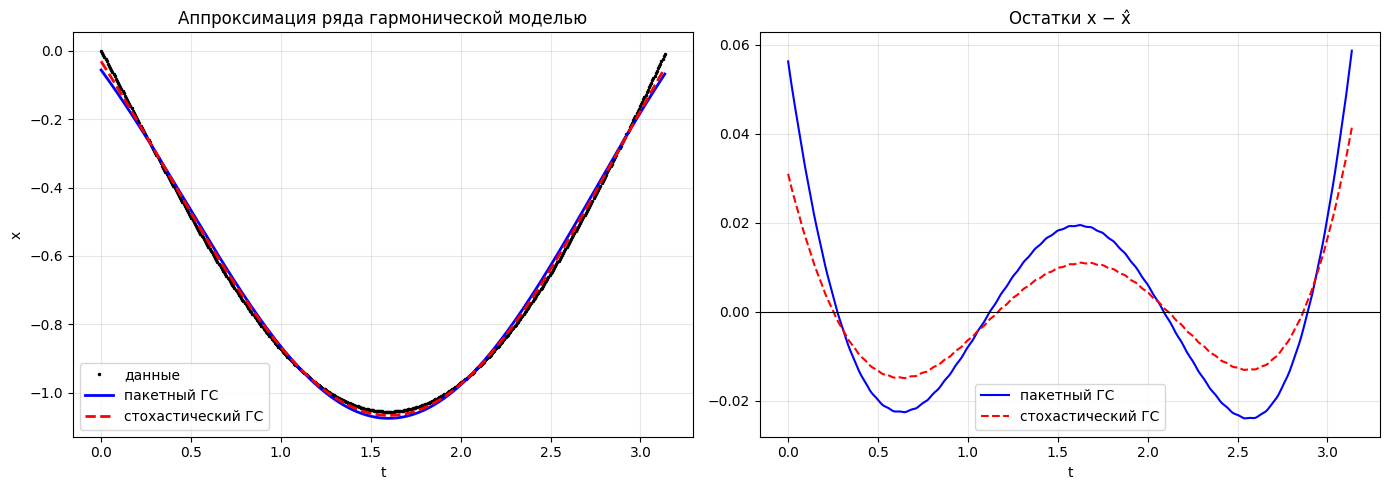

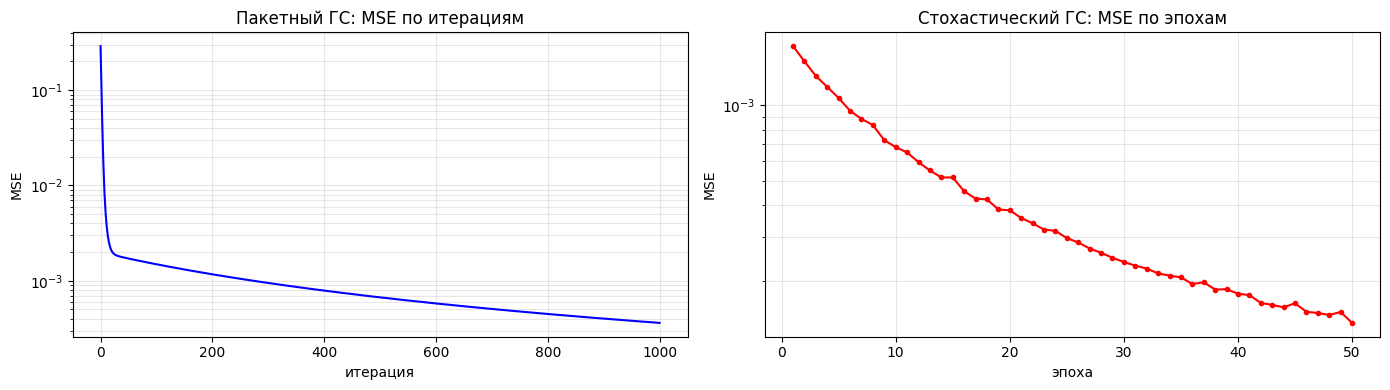

In [40]:
# 5. Графики
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(t, x, 'k.', ms=3, label='данные')
ax[0].plot(t, harmonic_model(p_batch, t), 'b-', lw=2, label='пакетный ГС')
ax[0].plot(t, harmonic_model(p_sgd, t), 'r--', lw=2, label='стохастический ГС')
ax[0].set_title('Аппроксимация ряда гармонической моделью')
ax[0].set_xlabel('t'); ax[0].set_ylabel('x')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(t, x - harmonic_model(p_batch, t), 'b-', label='пакетный ГС')
ax[1].plot(t, x - harmonic_model(p_sgd, t), 'r--', label='стохастический ГС')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('Остатки x − x̂')
ax[1].set_xlabel('t'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].semilogy(h_batch, 'b-')
ax[0].set_title('Пакетный ГС: MSE по итерациям')
ax[0].set_xlabel('итерация'); ax[0].set_ylabel('MSE'); ax[0].grid(alpha=0.3, which='both')
ax[1].semilogy(range(1, len(h_sgd)+1), h_sgd, 'r.-')
ax[1].set_title('Стохастический ГС: MSE по эпохам')
ax[1].set_xlabel('эпоха'); ax[1].set_ylabel('MSE'); ax[1].grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()